# Host attribution of *Salmonella* Typhimurium: the whole pipeline, step by step

You run every cell yourself, top to bottom (`Shift+Enter` runs a cell). Each step has a short explanation of **what** the code does and **why**. At the end there are exercises.

**Before you start**
1. Install the libraries once, in a VS Code terminal: `pip install pandas numpy scikit-learn matplotlib jupyter`
2. Put the two EnteroBase files in a folder called `data/` next to this notebook: `Allele_Profiles_FR.txt` and `Metadata_FR.txt`.
3. In VS Code, install the *Python* and *Jupyter* extensions, then pick a Python kernel (top right of the notebook).

**Running in Google Colab instead:** no installation needed. Put the data in Google Drive under `Host-Identification-Project/data/` and run the *Connect Google Drive* cell below the imports first.

**The pipeline**
load → check → clean → label → cap per cluster → model → cross-validate → measure → test for confounders

## 0. Imports
A library is a toolbox. `pandas` handles tables, `numpy` handles numbers, `scikit-learn` (`sklearn`) has the Random Forest, cross-validation and metrics, `matplotlib` draws plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option("display.width", 140)

In [2]:
# Connect Google Drive so the notebook can read the data files saved there
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/Host-Identification-Project')
print("Files in data/:", os.listdir('data'))

Mounted at /content/drive
Files in data/: ['Metadata_FR.txt', 'Allele_Profiles_FR.txt']


## 1. Load the data and look at it

Always look at your data before doing anything with it. Two tables:
- **alleles**: one row per isolate, one column per cgMLST locus. A number is the allele type at that gene. These are the *features* (the inputs the model learns from).
- **meta**: one row per isolate with source type, country, year and the HierCC cluster IDs (HC20, HC100, ...).

In [3]:
alleles = pd.read_csv("data/Allele_Profiles_FR.txt", sep="\t", low_memory=False)
meta    = pd.read_csv("data/Metadata_FR.txt",        sep="\t", low_memory=False)

print("alleles:", alleles.shape, "  meta:", meta.shape)
alleles.iloc[:3, :8]

alleles: (712, 3004)   meta: (712, 47)


,Name,ST,SC0831,SEN0401,SNSL254_A1382,SPAB_04503,STM0834,STM0942
0,2011-60-170-1,39358,1,10,1,4,1,1
1,2011-60-1822-1,39357,1,10,1,4,1,1
2,2011-60-1378-1,39355,1,10,1,4,1,1


In [4]:
meta[["Name", "Barcode", "Source Type", "Country", "Collection Year", "ST", "HC20", "HC100"]].head()

,Name,Barcode,Source Type,Country,Collection Year,ST,HC20,HC100
0,2011-60-170-1,SAL_AA7401AA,Swine,Denmark,2011,39358,39358,2
1,2011-60-1822-1,SAL_AA7402AA,Swine,Denmark,2011,39357,39357,41
2,2011-60-1378-1,SAL_AA7404AA,Swine,Denmark,2011,39355,39317,201
3,2011-60-1355-1,SAL_AA7405AA,Swine,Denmark,2011,39354,5062,41
4,2011-60-1341-1,SAL_AA7406AA,Swine,Denmark,2011,39353,39353,201


## 2. Check that the two tables line up

The model needs row *i* of the allele table to be the same isolate as row *i* of the metadata. The allele file has no barcode, so you cannot join on a unique ID. Joining on `Name` is **unsafe** because some names appear twice (re-sequenced isolates). So we check that the two files are in the same order, using both `Name` and `ST`. If this check passed, positions match. If it ever fails, stop and work out why before going on.

In [5]:
print("Duplicated names in meta:", meta["Name"].duplicated().sum())
same_order = (alleles["Name"].values == meta["Name"].values).all() and (alleles["ST"].values == meta["ST"].values).all()
print("Same row order in both files:", same_order)
assert same_order, "Files are not aligned - do not continue"

Duplicated names in meta: 9
Same row order in both files: True


## 3. Clean the alleles

Allele files contain `-` (locus not called) and sometimes `-1`. A Random Forest needs numbers only, so we turn everything into numbers and code "missing" as `-1`.

Two more steps:
- `errors="coerce"` turns anything that is not a number (like `-`) into `NaN` (not-a-number).
- Loci with the **same value in every isolate** carry no information, so we drop them.

This is a simple choice. Whether "missing" should be handled differently is a thesis-level question you could discuss with Robert.

In [6]:
locus_cols = alleles.columns[2:]                              # everything after Name and ST
X = alleles[locus_cols].apply(pd.to_numeric, errors="coerce")

print("Cells that were not numbers (e.g. '-'):", int(X.isna().sum().sum()))
X = X.fillna(-1).astype(int)

n_before = X.shape[1]
X = X.loc[:, X.nunique() > 1]
print(f"Loci kept: {X.shape[1]} of {n_before}  (dropped {n_before - X.shape[1]} constant loci)")

Cells that were not numbers (e.g. '-'): 277
Loci kept: 2868 of 3002  (dropped 134 constant loci)


## 4. Make the class labels (the host we want to predict)

The label is called `y` (the thing we predict); the features are `X`. The classes are chosen from `Source Type`:
- `Poultry`, `Swine`, `Bovine` stay as they are
- `Avian` (wild birds) → `Wild_birds`. It is kept separate from `Poultry` (farmed birds): the two share broad HC100 lineages but mostly not HC20 clusters (see 4.1), and we want to compare wild and livestock hosts
- `Canine`, `Equine`, `Feline`, `Ovine/Goat (Caprinae)`, `Deer (Cervidae)` → `Other_mammals` (each is too small alone)

In [13]:
# Poultry (farmed birds) and Avian (wild birds) are kept separate:
# they share HC100 lineages but mostly not HC20 clusters, and we want to compare wild vs livestock hosts.
label_map = {"Swine": "Swine", "Bovine": "Bovine", "Poultry": "Poultry", "Avian": "Wild_birds"}

# Safety check: make sure we know every Source Type that appears
other_types = {"Canine", "Equine", "Feline", "Ovine/Goat (Caprinae)", "Deer (Cervidae)"}
assert set(meta["Source Type"].unique()) <= set(label_map) | other_types, "unexpected Source Type"

meta["host"] = meta["Source Type"].map(label_map).fillna("Other_mammals")
meta["host"].value_counts()

,count
host,
Swine,280
Wild_birds,165
Poultry,162
Bovine,53
Other_mammals,52


In [14]:
# 4.1 Lineage check
# Do Poultry and Avian isolates fall in the same clusters?
for level in ["HC20", "HC100"]:
    birds = meta[meta["Source Type"].isin(["Poultry", "Avian"])]
    poultry_clusters = set(birds.loc[birds["Source Type"] == "Poultry", level])
    avian = birds[birds["Source Type"] == "Avian"]
    shared = avian[level].isin(poultry_clusters).mean()
    print(f"{level}: {len(avian)} Avian isolates, {shared:.0%} of them are in a cluster that also has Poultry")

HC20: 165 Avian isolates, 21% of them are in a cluster that also has Poultry
HC100: 165 Avian isolates, 93% of them are in a cluster that also has Poultry


In [15]:
sizes = meta["HC100"].value_counts()
print("Number of HC100 clusters:", len(sizes))
print("Share of isolates in the largest HC100 cluster:", round(sizes.iloc[0] / len(meta), 2))

Number of HC100 clusters: 31
Share of isolates in the largest HC100 cluster: 0.14


## 5. Cap the number of isolates per HC20 cluster

**Why:** isolates in the same HC20 cluster are near-clones. A few huge clusters would dominate the training data and make the model look better than it is (it would just recognise the clone). Keeping at most *N* isolates per cluster reduces that.

**How it works (read this carefully, it is the whole trick):**
1. Shuffle all rows randomly. `random_state=42` is the **seed**: the same seed gives the same shuffle, so anyone re-running your notebook gets the same result.
2. Group rows by cluster and keep the first *N* rows of each group (`.head(N)`). Because the rows were shuffled first, those *N* are a random sample.

The data you downloaded was already capped at 10 per cluster, so with `CAP = 10` nothing changes. To see the cap do something, change `CAP` to `3` and watch the numbers.

In [16]:
def cap_per_cluster(df, cluster_col, cap, seed=42):
    shuffled = df.sample(frac=1, random_state=seed)        # step 1: random order
    return shuffled.groupby(cluster_col).head(cap)         # step 2: first `cap` of each cluster

CAP = 10
sizes = meta["HC20"].value_counts()
print("Clusters:", len(sizes), "| largest cluster:", sizes.max(), "| clusters bigger than CAP:", (sizes > CAP).sum())

kept = cap_per_cluster(meta, "HC20", CAP).index.sort_values()
print(f"Isolates before: {len(meta)}  after cap {CAP}: {len(kept)}")

# Apply the cap to BOTH tables using the same row labels
meta_c = meta.loc[kept].reset_index(drop=True)
X_c    = X.loc[kept].reset_index(drop=True)
meta_c["host"].value_counts()

Clusters: 320 | largest cluster: 10 | clusters bigger than CAP: 0
Isolates before: 712  after cap 10: 712


,count
host,
Swine,280
Wild_birds,165
Poultry,162
Bovine,53
Other_mammals,52


**Practising on the full dataset (recommended).** To really see what the cap does, export workspace **168341** (2,131 isolates, before capping) from EnteroBase the same way as before, save as `Allele_Profiles_full.txt` and `Metadata_full.txt`, load them in section 1 instead, and run this section with `CAP = 10`. You should get roughly 700 isolates, close to but not exactly my 712, because my random shuffle was done in a different program.

## 6. Look at the problem before modelling

Two quick checks that will matter later: how big are the classes, and how much of the data comes from one country.

In [17]:
print(meta_c["host"].value_counts(), "\n")
print(meta_c["Country"].value_counts().head(6))

host
Swine            280
Wild_birds       165
Poultry          162
Bovine            53
Other_mammals     52
Name: count, dtype: int64 

Country
Germany           397
Poland             82
United Kingdom     50
Denmark            45
England            30
Ireland            27
Name: count, dtype: int64


## 7. Your first Random Forest (simple train/test split)

The idea: hide some isolates, train on the rest, then see whether the model predicts the hidden ones correctly.

- `stratify=y` keeps the class proportions the same in both parts.
- `class_weight="balanced"` makes mistakes on small classes count more, so the model doesn't just guess the biggest class.
- `n_estimators=300` is the number of trees. More is more stable but slower.
- **Balanced accuracy** is the average of the per-class recall. A model that always says "Swine" gets high plain accuracy here but poor balanced accuracy.

In [18]:
y = meta_c["host"]
groups = meta_c["HC20"]

X_train, X_test, y_train, y_test = train_test_split(X_c, y, test_size=0.25, stratify=y, random_state=0)

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print("Plain accuracy   :", round((pred == y_test).mean(), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pred), 3))

Plain accuracy   : 0.669
Balanced accuracy: 0.576


That number is **one** random split, and the test isolates may have close relatives in the training set. Don't trust it by itself. Cross-validation fixes the first problem, and *grouped* cross-validation fixes the second.

## 8. Cross-validation, random vs. grouped

**Cross-validation (CV):** cut the data into 5 parts ("folds"). Train on 4, test on the 1 you held out, and rotate until every isolate has been tested once. You get a prediction for every isolate that came from a model that never saw it.

- **Random CV** (`StratifiedKFold`): isolates are shuffled into folds. Relatives can land in both train and test, so it is optimistic.
- **Grouped CV** (`StratifiedGroupKFold`): all isolates of a cluster go into the *same* fold. The test fold only contains clusters the model has never seen, which is a harder and more honest test.

We write the loop ourselves so you can see exactly what happens.

In [19]:
def cv_predict(X, y, groups, grouped, seed=0, n_splits=5, n_trees=300):
    if grouped:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    else:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    pred = np.empty(len(y), dtype=object)
    for train_idx, test_idx in cv.split(X, y, groups if grouped else None):
        model = RandomForestClassifier(n_estimators=n_trees, class_weight="balanced",
                                       n_jobs=-1, random_state=seed)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred[test_idx] = model.predict(X.iloc[test_idx])
    return pred

**Verify that grouping really works.** Never assume; check that no cluster appears on both sides of any split.

In [20]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
overlaps = sum(len(set(groups.iloc[tr]) & set(groups.iloc[te])) for tr, te in cv.split(X_c, y, groups))
print("Clusters present in both train and test (grouped CV):", overlaps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
overlaps = sum(len(set(groups.iloc[tr]) & set(groups.iloc[te])) for tr, te in cv.split(X_c, y))
print("Clusters present in both train and test (random CV)  :", overlaps)

Clusters present in both train and test (grouped CV): 0
Clusters present in both train and test (random CV)  : 329


## 9. Measure performance properly

With imbalanced classes, plain accuracy misleads. Report several metrics:
- **Balanced accuracy**: mean recall per class. Chance = 1 / number of classes.
- **Cohen's kappa** and **MCC**: agreement beyond chance, from 0 (chance) to 1 (perfect).
- **Confusion matrix**: rows = true host, columns = predicted host. This shows *which* hosts get confused.

Cross-validation has randomness (which isolates fall in which fold), so repeat with a few seeds and report mean ± spread.

In [21]:
def scores(y_true, y_pred):
    return {"balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred),
            "mcc": matthews_corrcoef(y_true, y_pred)}

results, preds = [], {}
for grouped in [False, True]:
    for seed in [0, 1, 2]:
        p = cv_predict(X_c, y, groups, grouped=grouped, seed=seed)
        results.append({"CV": "grouped by HC20" if grouped else "random", "seed": seed, **scores(y, p)})
        preds[("grouped" if grouped else "random", seed)] = p

res = pd.DataFrame(results)
res.groupby("CV")[["balanced_acc", "kappa", "mcc"]].agg(["mean", "std"]).round(3)

balanced_acc         kappa           mcc       
                        mean    std   mean    std   mean    std
CV                                                             
grouped by HC20        0.384  0.006  0.378  0.009  0.381  0.009
random                 0.586  0.008  0.589  0.008  0.590  0.008

Chance level for balanced accuracy with 5 classes: 0.20


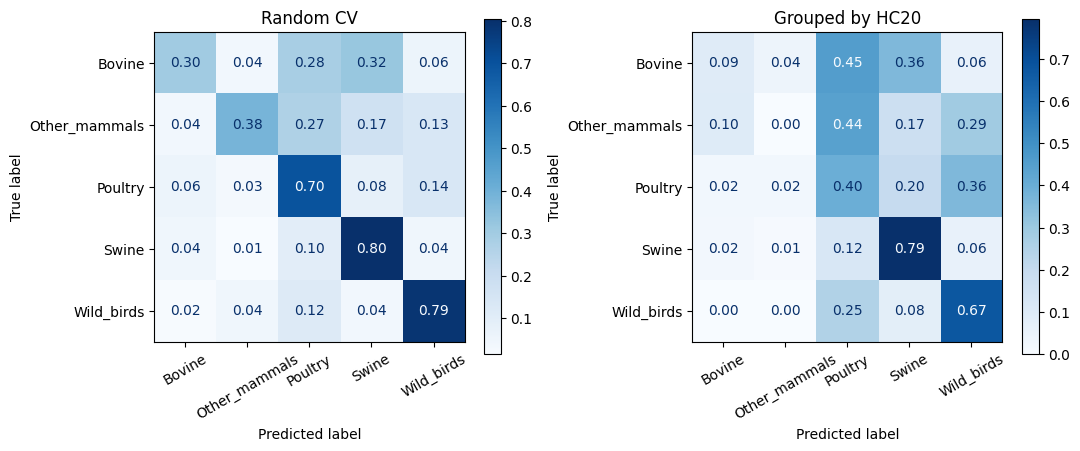

In [22]:
chance = 1 / y.nunique()
print(f"Chance level for balanced accuracy with {y.nunique()} classes: {chance:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key in zip(axes, [("random", 0), ("grouped", 0)]):
    ConfusionMatrixDisplay.from_predictions(y, preds[key], normalize="true", ax=ax,
                                            cmap="Blues", values_format=".2f", xticks_rotation=30)
    ax.set_title("Random CV" if key[0] == "random" else "Grouped by HC20")
plt.tight_layout(); plt.show()

Read the right-hand matrix by rows: each row shows what happened to isolates of that true host. The diagonal is the proportion correct (recall). Which classes are learned, and which are mostly mistaken for another class?

## 10. Is the model learning host, or just country?

Germany contributes more than half of the isolates. If country and host are tangled up, a model could do reasonably well knowing nothing about the genome. Test this directly: a model that sees **only** the country (one-hot encoded) and uses the same grouped CV.

In [23]:
X_country = pd.get_dummies(meta_c["Country"]).astype(int)
p_country = cv_predict(X_country, y, groups, grouped=True, seed=0)
print("Country-only model, grouped CV ->", {k: round(v, 3) for k, v in scores(y, p_country).items()})
print("Genome model, grouped CV       ->", res[res.CV == "grouped by HC20"][["balanced_acc", "kappa", "mcc"]].mean().round(3).to_dict())

Country-only model, grouped CV -> {'balanced_acc': np.float64(0.293), 'kappa': np.float64(0.178), 'mcc': np.float64(0.193)}
Genome model, grouped CV       -> {'balanced_acc': 0.384, 'kappa': 0.378, 'mcc': 0.381}


If the country-only model is close to the genome model, the genome model is probably exploiting country (or sampling structure), and the result cannot be claimed as a genomic host signal. Compare the two numbers and write down what you conclude.

## 11. Which loci does the model use?

A Random Forest gives each locus an *importance* (how much it helped the trees separate classes). Train once on all data and list the top ones. Importances are descriptive only. They do not prove a locus is causal, and they are inflated when loci are correlated, which is typical in bacterial genomes.

In [24]:
final = RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=0).fit(X_c, y)
imp = pd.Series(final.feature_importances_, index=X_c.columns).sort_values(ascending=False)
imp.head(10).round(4)

,0
STMMW_22841,0.0130
STMMW_42261,0.0042
STMMW_42461,0.0031
STMMW_04461,0.0030
STMMW_02371,0.0027
STMMW_39361,0.0026
STMMW_07971,0.0026
STMMW_04651,0.0025
STMMW_24541,0.0025
STMMW_28021,0.0025


## 12. Exercises (these are the actual thesis work)

1. **Cap sensitivity.** Run the whole notebook with `CAP = 3`, `10` and `20` (needs the full-dataset export, see section 5). Does the grouped balanced accuracy change much? Tabulate the results.
2. **Drop `Other_mammals`.** Remove those isolates before modelling (`meta_c = meta_c[meta_c.host != "Other_mammals"]` and subset `X_c` the same way). What changes?
3. **A stricter grouping.** In `cv_predict`, use `meta_c["HC100"]` instead of `HC20` as the groups. If performance falls further, part of the earlier signal was just lineage.
4. **Hold out a country.** Train on every country except Germany and test on Germany (and the reverse). This asks whether the model transfers.
5. **A second method.** Replace `RandomForestClassifier` with `sklearn.ensemble.HistGradientBoostingClassifier` or `xgboost.XGBClassifier`, keeping everything else identical.
6. **Write down** for each result: what you changed, what you expected, what happened, and why. That log is the skeleton of your Methods and Results sections.